# K-Means concurrente, integración y rendimiento en Go

Trabaja por separado con 445 347 vectores de una hora y 18 297 de 24 horas, en el orden `[PM10, PM2.5]`, sin escalado. Estas cantidades no equivalen a las 1 062 897 mediciones del cargador.



## 1. Configuración del entorno

El modelo se ejecuta en Go; Python solo organiza las ejecuciones y presenta las tablas y figuras. Se fija GOMAXPROCS=4 para comparar ambos modos bajo la misma configuración.


In [1]:
import os, sys, subprocess, json, hashlib, random, statistics
from pathlib import Path
from datetime import datetime, timezone

subprocess.run(['apt-get', 'update', '-qq'], check=True)
subprocess.run(['apt-get', 'install', '-y', '-qq', 'golang-go', 'gcc'], check=True)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pandas', 'matplotlib'], check=True)
os.chdir('/content')
os.environ['GOMAXPROCS']='4'
os.environ['CGO_ENABLED']='1'
os.environ['CC']='gcc'
for command in [['go','version'],['uname','-sr'],['lscpu'],['free','-h']]:
    print('$', ' '.join(command), flush=True)
    subprocess.run(command, check=True)
print('Fecha UTC:',datetime.now(timezone.utc).isoformat())
print('GOMAXPROCS:',os.environ['GOMAXPROCS'])


$ go version
$ uname -sr
$ lscpu
$ free -h
Fecha UTC: 2026-11-07T08:55:30.985885+00:00
GOMAXPROCS: 4


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [16]:
from pathlib import Path
import urllib.request
import hashlib
import os
import pandas as pd
from IPython.display import display
VECTOR_DIR = Path('/content')
DRIVE_FILES = {
    '1_hora': ('1oHqxofkw5IXPefc8BDJVM8Z5EfcKE024', 445347,
               '2996aeea838e11ebb0613034ceabd7a51c0a7df9ba1a83f8657f908bfb267204'),
    '24_horas': ('10XM6ZWiFNhnzNk13wRhZY5TqkQEReczD', 18297,
                 '5866449404c20a23e52b65f94871a365c7979b1fcf0abd7ed91554d70ea609a6')
}
FILES = {}
data_info = []
for period, (file_id, expected_rows, expected_hash) in DRIVE_FILES.items():
    path = VECTOR_DIR / f'features_{period}.csv'
    url = f'https://drive.google.com/uc?export=download&id={file_id}'
    with urllib.request.urlopen(url, timeout=120) as response:
        content = response.read()
    actual_hash = hashlib.sha256(content).hexdigest()
    if actual_hash != expected_hash:
        raise ValueError(f'{period}: la descarga no coincide con el CSV verificado. Revisa el acceso; no continúes con una página HTML o datos diferentes.')
    path.write_bytes(content)
    frame = pd.read_csv(path)
    assert list(frame.columns) == ['PM10', 'PM2.5'], 'Encabezado inesperado'
    assert len(frame) == expected_rows, f'Conteo inesperado: {period}'
    FILES[period] = path
    data_info.append({'Periodo': period, 'Vectores': len(frame),
                      'Características': 2, 'Archivo': str(path), 'SHA256': actual_hash})
    del frame
os.environ['KMEANS_VECTOR_DIR'] = str(VECTOR_DIR)
display(pd.DataFrame(data_info))
print('Los dos CSV de Drive están listos para ejecutar el modelo.')

,Periodo,Vectores,Características,Archivo,SHA256
0,1_hora,445347,2,/content/features_1_hora.csv,2996aeea838e11ebb0613034ceabd7a51c0a7df9ba1a83...
1,24_horas,18297,2,/content/features_24_horas.csv,5866449404c20a23e52b65f94871a365c7979b1fcf0abd...


Los dos CSV de Drive están listos para ejecutar el modelo.


## 3. Estructura de datos y lector reutilizados

`dataset.go` mantiene dos dimensiones y el número de observaciones. `loader.go` lee el CSV respetando su formato, comprueba el encabezado y rechaza datos vacíos, valores no numéricos y no finitos. Ambos son los archivos de la referencia del equipo. La integración conecta este lector de vectores con los dos modelos; no transforma las estadísticas del cargador de mediciones en vectores.


In [17]:
%%writefile /content/dataset.go
package main

// Dimensions representa la cantidad de características
// que utilizaremos para cada observación: PM10 y PM2.5.
const Dimensions = 2

// Dataset almacena los vectores que utilizaremos en K-Means.
type Dataset struct {
	Points [][]float64
	N      int
	D      int
}

// NewDataset crea un conjunto de datos a partir de una lista de puntos.
func NewDataset(points [][]float64) Dataset {
	return Dataset{
		Points: points,
		N:      len(points),
		D:      Dimensions,
	}
}


Overwriting /content/dataset.go


In [18]:
%%writefile /content/loader.go
package main

import (
	"encoding/csv"
	"fmt"
	"io"
	"math"
	"os"
	"strconv"
)

// LoadCSV lee un archivo CSV con las columnas PM10 y PM2.5.
func LoadCSV(path string) (Dataset, error) {
	file, err := os.Open(path)
	if err != nil {
		return Dataset{}, fmt.Errorf("no se pudo abrir el archivo: %w", err)
	}
	defer file.Close()

	reader := csv.NewReader(file)

	header, err := reader.Read()
	if err != nil {
		return Dataset{}, fmt.Errorf("no se pudo leer el encabezado: %w", err)
	}

	if len(header) != 2 || header[0] != "PM10" || header[1] != "PM2.5" {
		return Dataset{}, fmt.Errorf("formato de CSV incorrecto: se esperaban PM10 y PM2.5")
	}

	points := make([][]float64, 0)

	for row := 2; ; row++ {
		record, err := reader.Read()

		if err == io.EOF {
			break
		}

		if err != nil {
			return Dataset{}, fmt.Errorf("error al leer la fila %d: %w", row, err)
		}

		if len(record) != 2 {
			return Dataset{}, fmt.Errorf("la fila %d debe tener exactamente 2 columnas", row)
		}

		pm10, err := strconv.ParseFloat(record[0], 64)
		if err != nil {
			return Dataset{}, fmt.Errorf("valor PM10 inválido en la fila %d: %w", row, err)
		}

		pm25, err := strconv.ParseFloat(record[1], 64)
		if err != nil {
			return Dataset{}, fmt.Errorf("valor PM2.5 inválido en la fila %d: %w", row, err)
		}

		if math.IsNaN(pm10) || math.IsInf(pm10, 0) ||
			math.IsNaN(pm25) || math.IsInf(pm25, 0) {
			return Dataset{}, fmt.Errorf("se encontró un valor no finito en la fila %d", row)
		}

		points = append(points, []float64{pm10, pm25})
	}

	if len(points) == 0 {
		return Dataset{}, fmt.Errorf("el CSV no contiene datos")
	}

	return NewDataset(points), nil
}


Overwriting /content/loader.go


## 4. Referencia secuencial — `kmeans.go`

Se reutiliza la referencia para comprobar la implementación concurrente. Ambas versiones usan K=4, semilla=42, máximo de 100 iteraciones, tolerancia=0.001, distancia euclidiana y la misma inicialización. Un clúster vacío conserva su centroide anterior y un empate favorece al primero. La convergencia se cumple cuando el movimiento conjunto es estrictamente menor que la tolerancia.


In [19]:
%%writefile /content/kmeans.go
package main

import (
	"fmt"
	"math"
	"math/rand"
)

// initializeCentroids selecciona K puntos aleatorios del dataset
// para utilizarlos como centroides iniciales.
func initializeCentroids(data Dataset, k int, seed int64) ([][]float64, error) {
	if err := validateDataset(data); err != nil {
		return nil, err
	}

	if k <= 0 || k > data.N {
		return nil, fmt.Errorf("K debe estar entre 1 y N")
	}

	rng := rand.New(rand.NewSource(seed))
	indices := rng.Perm(data.N)[:k]

	centroids := make([][]float64, k)

	for i, index := range indices {
		centroids[i] = make([]float64, data.D)
		copy(centroids[i], data.Points[index])
	}

	return centroids, nil
}

// validateDataset comprueba que el conjunto de datos tenga
// una estructura válida para trabajar con K-Means.
func validateDataset(data Dataset) error {
	if data.N <= 0 || len(data.Points) == 0 {
		return fmt.Errorf("el conjunto de datos está vacío")
	}

	if data.N != len(data.Points) {
		return fmt.Errorf("la cantidad de puntos no coincide con N")
	}

	if data.D != 2 {
		return fmt.Errorf("el dataset debe tener exactamente 2 dimensiones")
	}

	for i, point := range data.Points {
		if len(point) != data.D {
			return fmt.Errorf("el punto %d tiene dimensiones inconsistentes", i)
		}

		for _, value := range point {
			if math.IsNaN(value) || math.IsInf(value, 0) {
				return fmt.Errorf("el punto %d contiene un valor no finito", i)
			}
		}
	}

	return nil
}

// squaredDistance calcula la distancia euclidiana al cuadrado
// entre dos puntos.
func squaredDistance(a, b []float64) float64 {
	var distance float64

	for i := range a {
		diff := a[i] - b[i]
		distance += diff * diff
	}

	return distance
}

// assignClusters asigna cada punto al clúster cuyo centroide
// se encuentra más cerca.
func assignClusters(data Dataset, centroids [][]float64) []int {
	labels := make([]int, data.N)

	for i, point := range data.Points {
		bestCluster := 0
		minDistance := squaredDistance(point, centroids[0])

		for j := 1; j < len(centroids); j++ {
			distance := squaredDistance(point, centroids[j])

			if distance < minDistance {
				minDistance = distance
				bestCluster = j
			}
		}

		labels[i] = bestCluster
	}

	return labels
}

// updateCentroids actualiza los centroides calculando el promedio
// de los puntos asignados a cada clúster.
// Si un clúster queda vacío, conserva su centroide anterior.
func updateCentroids(data Dataset, labels []int, centroids [][]float64) [][]float64 {
	k := len(centroids)

	newCentroids := make([][]float64, k)
	counts := make([]int, k)

	for i := range newCentroids {
		newCentroids[i] = make([]float64, data.D)
	}

	// Acumulamos los valores de cada dimensión por clúster.
	for i, point := range data.Points {
		cluster := labels[i]
		counts[cluster]++

		for d := 0; d < data.D; d++ {
			newCentroids[cluster][d] += point[d]
		}
	}

	// Calculamos el promedio de cada clúster.
	for cluster := 0; cluster < k; cluster++ {
		if counts[cluster] > 0 {
			for d := 0; d < data.D; d++ {
				newCentroids[cluster][d] /= float64(counts[cluster])
			}
		} else {
			copy(newCentroids[cluster], centroids[cluster])
		}
	}

	return newCentroids
}

// KMeansResult almacena los resultados obtenidos al ejecutar K-Means.
type KMeansResult struct {
	Centroids  [][]float64
	Labels     []int
	Inertia    float64
	Iterations int
	Converged  bool
}

// calculateInertia calcula la suma de las distancias al cuadrado
// entre cada punto y el centroide de su clúster.
func calculateInertia(data Dataset, centroids [][]float64, labels []int) float64 {
	var inertia float64

	for i, point := range data.Points {
		inertia += squaredDistance(point, centroids[labels[i]])
	}

	return inertia
}

// RunKMeans ejecuta el algoritmo K-Means secuencial.
func RunKMeans(data Dataset, k int, maxIter int, tol float64, seed int64) (KMeansResult, error) {
	if err := validateDataset(data); err != nil {
		return KMeansResult{}, err
	}

	if k <= 0 || k > data.N {
		return KMeansResult{}, fmt.Errorf("K debe estar entre 1 y N")
	}

	if maxIter <= 0 {
		return KMeansResult{}, fmt.Errorf("el máximo de iteraciones debe ser positivo")
	}

	if tol < 0 || math.IsNaN(tol) || math.IsInf(tol, 0) {
		return KMeansResult{}, fmt.Errorf("la tolerancia debe ser finita y no negativa")
	}

	centroids, err := initializeCentroids(data, k, seed)
	if err != nil {
		return KMeansResult{}, err
	}

	result := KMeansResult{}

	for iteration := 0; iteration < maxIter; iteration++ {
		labels := assignClusters(data, centroids)
		newCentroids := updateCentroids(data, labels, centroids)

		var movement float64

		for cluster := 0; cluster < k; cluster++ {
			movement += squaredDistance(centroids[cluster], newCentroids[cluster])
		}

		centroids = newCentroids
		result.Iterations = iteration + 1

		if math.Sqrt(movement) < tol {
			result.Converged = true
			break
		}
	}

	// Reasignamos los puntos usando los centroides finales.
	result.Centroids = centroids
	result.Labels = assignClusters(data, centroids)
	result.Inertia = calculateInertia(data, centroids, result.Labels)

	return result, nil
}


Overwriting /content/kmeans.go


## 5. Implementación concurrente — `concurrent.go`

Las observaciones se dividen en rangos contiguos sin huecos ni solapamientos. Los primeros N mod P rangos reciben una fila adicional; si hay más workers que puntos, P se limita a N. Para 445 347 filas y cuatro workers, los bloques contienen 111 337, 111 337, 111 337 y 111 336 filas.

Cada goroutine consulta los mismos centroides y mantiene sumas y conteos privados. Escribe únicamente las etiquetas de su rango. `WaitGroup` establece la barrera; después se reducen los acumuladores en orden de worker y se actualizan los centroides. Se usa partición estática por iteración, no una cola de trabajos persistente. No se necesitan canales ni mutex en este cálculo


In [21]:
%%writefile /content/concurrent.go
package main

import (
	"fmt"
	"math"
	"sync"
)

type rowRange struct{ start, end int }

// partitionRows reparte el resto entre los primeros rangos, sin bloques vacíos.
func partitionRows(n, workers int) []rowRange {
	if n <= 0 || workers <= 0 {
		return nil
	}
	if workers > n {
		workers = n
	}
	ranges := make([]rowRange, workers)
	start := 0
	for w := range ranges {
		size := n / workers
		if w < n%workers {
			size++
		}
		ranges[w] = rowRange{start, start + size}
		start += size
	}
	return ranges
}

type partial struct {
	sums   [][Dimensions]float64
	counts []int
}

// concurrentAssignment usa rangos estáticos, no una cola de trabajos.
// Cada goroutine escribe solo su segmento de labels y su acumulador privado.
func concurrentAssignment(data Dataset, centroids [][]float64, ranges []rowRange) ([]int, []partial) {
	labels := make([]int, data.N)
	parts := make([]partial, len(ranges))
	var wg sync.WaitGroup
	for w, rows := range ranges {
		wg.Add(1)
		go func(w int, rows rowRange) {
			defer wg.Done()
			p := partial{make([][Dimensions]float64, len(centroids)), make([]int, len(centroids))}
			for i := rows.start; i < rows.end; i++ {
				point := data.Points[i]
				best := 0
				distance := squaredDistance(point, centroids[0])
				for c := 1; c < len(centroids); c++ {
					if d := squaredDistance(point, centroids[c]); d < distance {
						best, distance = c, d
					}
				}
				labels[i] = best
				p.counts[best]++
				for d := 0; d < Dimensions; d++ {
					p.sums[best][d] += point[d]
				}
			}
			parts[w] = p
		}(w, rows)
	}
	wg.Wait()
	return labels, parts
}

func reduceCentroids(parts []partial, previous [][]float64) [][]float64 {
	centroids := make([][]float64, len(previous))
	for c := range previous {
		centroids[c] = make([]float64, Dimensions)
		count := 0
		// Orden fijo de worker: no depende del orden de finalización.
		for _, p := range parts {
			count += p.counts[c]
			for d := 0; d < Dimensions; d++ {
				centroids[c][d] += p.sums[c][d]
			}
		}
		if count == 0 {
			copy(centroids[c], previous[c])
		} else {
			for d := 0; d < Dimensions; d++ {
				centroids[c][d] /= float64(count)
			}
		}
	}
	return centroids
}

// RunKMeansConcurrent conserva el contrato y la inicialización de RunKMeans.
// El llamador no debe mutar data.Points durante la ejecución.
func RunKMeansConcurrent(data Dataset, k, maxIter int, tol float64, seed int64, workers int) (KMeansResult, error) {
	if err := validateDataset(data); err != nil {
		return KMeansResult{}, err
	}
	if k <= 0 || k > data.N {
		return KMeansResult{}, fmt.Errorf("K debe estar entre 1 y N")
	}
	if maxIter <= 0 {
		return KMeansResult{}, fmt.Errorf("el máximo de iteraciones debe ser positivo")
	}
	if tol < 0 || math.IsNaN(tol) || math.IsInf(tol, 0) {
		return KMeansResult{}, fmt.Errorf("la tolerancia debe ser finita y no negativa")
	}
	if workers <= 0 {
		return KMeansResult{}, fmt.Errorf("workers debe ser positivo")
	}
	centroids, err := initializeCentroids(data, k, seed)
	if err != nil {
		return KMeansResult{}, err
	}
	ranges := partitionRows(data.N, workers)
	result := KMeansResult{}
	for iteration := 0; iteration < maxIter; iteration++ {
		_, parts := concurrentAssignment(data, centroids, ranges)
		next := reduceCentroids(parts, centroids)
		var movement float64
		for c := range centroids {
			movement += squaredDistance(centroids[c], next[c])
		}
		centroids = next
		result.Iterations = iteration + 1
		if math.Sqrt(movement) < tol {
			result.Converged = true
			break
		}
	}
	result.Centroids = centroids
	result.Labels, _ = concurrentAssignment(data, centroids, ranges)
	// Misma suma en orden de observaciones que la referencia.
	result.Inertia = calculateInertia(data, centroids, result.Labels)
	return result, nil
}


Overwriting /content/concurrent.go


## 6. Integración y ejecución — `cli.go` y `main.go`

El comando común carga el archivo seleccionado y permite ejecutar `sequential` o `concurrent`. Separa carga, entrenamiento y tiempo total, y devuelve centroides, conteos, iteraciones, inercia y las asignaciones cuando se solicita `-labels`.

Los resultados conservan un hash de las etiquetas y los centroides iniciales para comparar las ejecuciones. El tiempo medido excluye la compilación, el arranque del proceso y la presentación de resultados.

In [22]:
%%writefile /content/cli.go
package main

import (
	"crypto/sha256"
	"encoding/binary"
	"encoding/hex"
	"encoding/json"
	"flag"
	"fmt"
	"io"
	"runtime"
	"time"
)

type execution struct {
	Period           string      `json:"period"`
	Input            string      `json:"input"`
	Mode             string      `json:"mode"`
	Vectors          int         `json:"vectors"`
	K                int         `json:"k"`
	MaxIterations    int         `json:"max_iterations"`
	Tolerance        float64     `json:"tolerance"`
	Seed             int64       `json:"seed"`
	WorkersRequested int         `json:"workers_requested"`
	WorkersEffective int         `json:"workers_effective"`
	GOMAXPROCS       int         `json:"gomaxprocs"`
	GoVersion        string      `json:"go_version"`
	InitialCentroids [][]float64 `json:"initial_centroids"`
	Centroids        [][]float64 `json:"centroids"`
	Counts           []int       `json:"counts"`
	Labels           []int       `json:"labels,omitempty"`
	LabelsSHA256     string      `json:"labels_sha256"`
	Iterations       int         `json:"iterations"`
	Converged        bool        `json:"converged"`
	Inertia          float64     `json:"inertia"`
	LoadSeconds      float64     `json:"load_seconds"`
	TrainSeconds     float64     `json:"train_seconds"`
	TotalSeconds     float64     `json:"total_seconds"`
}

func runCLI(args []string, output io.Writer) error {
	flags := flag.NewFlagSet("kmeans", flag.ContinueOnError)
	input := flags.String("input", "", "CSV de características PM10,PM2.5")
	period := flags.String("period", "", "Periodo explícito: 1_hora o 24_horas")
	mode := flags.String("mode", "sequential", "sequential o concurrent")
	workers := flags.Int("workers", 4, "Goroutines solicitadas")
	k := flags.Int("k", 4, "Número de clústeres")
	maxIter := flags.Int("max-iter", 100, "Máximo de iteraciones")
	tol := flags.Float64("tol", .001, "Tolerancia del movimiento")
	seed := flags.Int64("seed", 42, "Semilla compartida")
	labels := flags.Bool("labels", false, "Incluir todas las asignaciones en JSON")
	if err := flags.Parse(args); err != nil {
		return err
	}
	if flags.NArg() != 0 {
		return fmt.Errorf("no se admiten argumentos posicionales")
	}
	if *input == "" || (*period != "1_hora" && *period != "24_horas") {
		return fmt.Errorf("indique -input y -period=1_hora o 24_horas")
	}
	if *mode != "sequential" && *mode != "concurrent" {
		return fmt.Errorf("modo inválido: %s", *mode)
	}
	if *workers <= 0 {
		return fmt.Errorf("workers debe ser positivo")
	}
	start := time.Now()
	data, err := LoadCSV(*input)
	if err != nil {
		return err
	}
	load := time.Since(start)
	trainStart := time.Now()
	var result KMeansResult
	if *mode == "sequential" {
		result, err = RunKMeans(data, *k, *maxIter, *tol, *seed)
	} else {
		result, err = RunKMeansConcurrent(data, *k, *maxIter, *tol, *seed, *workers)
	}
	train := time.Since(trainStart)
	total := time.Since(start)
	if err != nil {
		return err
	}
	// Metadatos y serialización fuera del alcance medido de carga+modelo.
	initial, err := initializeCentroids(data, *k, *seed)
	if err != nil {
		return err
	}
	counts := make([]int, *k)
	h := sha256.New()
	var buf [8]byte
	for _, label := range result.Labels {
		counts[label]++
		binary.LittleEndian.PutUint64(buf[:], uint64(label))
		_, _ = h.Write(buf[:])
	}
	effective := 1
	if *mode == "concurrent" {
		effective = len(partitionRows(data.N, *workers))
	}
	report := execution{Period: *period, Input: *input, Mode: *mode, Vectors: data.N, K: *k, MaxIterations: *maxIter, Tolerance: *tol, Seed: *seed, WorkersRequested: *workers, WorkersEffective: effective, GOMAXPROCS: runtime.GOMAXPROCS(0), GoVersion: runtime.Version(), InitialCentroids: initial, Centroids: result.Centroids, Counts: counts, LabelsSHA256: hex.EncodeToString(h.Sum(nil)), Iterations: result.Iterations, Converged: result.Converged, Inertia: result.Inertia, LoadSeconds: load.Seconds(), TrainSeconds: train.Seconds(), TotalSeconds: total.Seconds()}
	if *labels {
		report.Labels = result.Labels
	}
	return json.NewEncoder(output).Encode(report)
}


Overwriting /content/cli.go


In [23]:
%%writefile /content/main.go
package main

import (
    "log"
    "os"
)

func main() {
    if err := runCLI(os.Args[1:], os.Stdout); err != nil { log.Fatal(err) }
}


Overwriting /content/main.go


## 7. Pruebas de partición, equivalencia e integración

Las pruebas con ambos datasets comparan directamente todas las etiquetas y exigen igual número de iteraciones y convergencia. Se permite una diferencia numérica de `1e-9 + 1e-9 × |referencia|` para centroides e inercia. La identidad de los clústeres queda fijada por la misma inicialización: no se permutan etiquetas para ocultar diferencias.


In [25]:
%%writefile /content/loader_test.go
package main

import (
	"os"
	"path/filepath"
	"testing"
)

func createCSV(t *testing.T, content string) string {
	t.Helper()

	path := filepath.Join(t.TempDir(), "test.csv")

	err := os.WriteFile(path, []byte(content), 0600)
	if err != nil {
		t.Fatalf("no se pudo crear el CSV: %v", err)
	}

	return path
}

func TestLoadCSVSuccess(t *testing.T) {
	path := createCSV(t, "PM10,PM2.5\n10.5,5.2\n20.0,8.5\n")

	data, err := LoadCSV(path)
	if err != nil {
		t.Fatalf("no se esperaba un error: %v", err)
	}

	if data.N != 2 {
		t.Errorf("se esperaban 2 puntos, se obtuvieron %d", data.N)
	}

	if data.D != 2 {
		t.Errorf("se esperaban 2 dimensiones, se obtuvieron %d", data.D)
	}

	if data.Points[0][0] != 10.5 || data.Points[0][1] != 5.2 {
		t.Errorf("valores incorrectos en el primer punto: %v", data.Points[0])
	}
}

func TestLoadCSVEmpty(t *testing.T) {
	path := createCSV(t, "PM10,PM2.5\n")

	_, err := LoadCSV(path)
	if err == nil {
		t.Fatal("se esperaba un error para un CSV sin registros")
	}
}

func TestLoadCSVInvalidHeader(t *testing.T) {
	path := createCSV(t, "PM10,NO2\n10,5\n")

	_, err := LoadCSV(path)
	if err == nil {
		t.Fatal("se esperaba un error por encabezado incorrecto")
	}
}

func TestLoadCSVInvalidValue(t *testing.T) {
	path := createCSV(t, "PM10,PM2.5\nabc,5\n")

	_, err := LoadCSV(path)
	if err == nil {
		t.Fatal("se esperaba un error por valor no numérico")
	}
}

func TestLoadCSVInvalidDimensions(t *testing.T) {
	path := createCSV(t, "PM10,PM2.5\n10\n")

	_, err := LoadCSV(path)
	if err == nil {
		t.Fatal("se esperaba un error por cantidad incorrecta de columnas")
	}
}


Overwriting /content/loader_test.go


In [26]:
%%writefile /content/kmeans_test.go
package main

import (
	"math"
	"reflect"
	"testing"
)

func TestInitializeCentroidsReproducible(t *testing.T) {
	data := NewDataset([][]float64{
		{1, 1},
		{2, 2},
		{10, 10},
		{11, 11},
	})

	first, err := initializeCentroids(data, 2, 42)
	if err != nil {
		t.Fatalf("error al inicializar: %v", err)
	}

	second, err := initializeCentroids(data, 2, 42)
	if err != nil {
		t.Fatalf("error al inicializar: %v", err)
	}

	if !reflect.DeepEqual(first, second) {
		t.Errorf("la inicialización no fue reproducible")
	}
}

func TestInitializeCentroidsInvalidK(t *testing.T) {
	data := NewDataset([][]float64{
		{1, 1},
		{2, 2},
	})

	invalidValues := []int{0, -1, 3}

	for _, k := range invalidValues {
		_, err := initializeCentroids(data, k, 42)
		if err == nil {
			t.Errorf("se esperaba un error para K=%d", k)
		}
	}
}

func TestAssignClusters(t *testing.T) {
	data := NewDataset([][]float64{
		{1, 1},
		{2, 2},
		{10, 10},
		{11, 11},
	})

	centroids := [][]float64{
		{1, 1},
		{10, 10},
	}

	labels := assignClusters(data, centroids)

	expected := []int{0, 0, 1, 1}

	if !reflect.DeepEqual(labels, expected) {
		t.Errorf("etiquetas incorrectas: se obtuvo %v, se esperaba %v", labels, expected)
	}
}

func TestUpdateCentroids(t *testing.T) {
	data := NewDataset([][]float64{
		{1, 1},
		{3, 3},
		{10, 10},
		{12, 12},
	})

	labels := []int{0, 0, 1, 1}

	centroids := [][]float64{
		{1, 1},
		{10, 10},
	}

	updated := updateCentroids(data, labels, centroids)

	expected := [][]float64{
		{2, 2},
		{11, 11},
	}

	if !reflect.DeepEqual(updated, expected) {
		t.Errorf("centroides incorrectos: se obtuvo %v", updated)
	}
}

func TestUpdateCentroidsEmptyCluster(t *testing.T) {
	data := NewDataset([][]float64{
		{1, 1},
		{2, 2},
	})

	labels := []int{0, 0}

	centroids := [][]float64{
		{1, 1},
		{10, 10},
	}

	updated := updateCentroids(data, labels, centroids)

	if !reflect.DeepEqual(updated[1], centroids[1]) {
		t.Errorf("el centroide del clúster vacío debería conservarse")
	}
}

func TestRunKMeans(t *testing.T) {
	data := NewDataset([][]float64{
		{1, 1},
		{2, 2},
		{10, 10},
		{11, 11},
	})

	result, err := RunKMeans(data, 2, 100, 0.001, 42)
	if err != nil {
		t.Fatalf("no se esperaba un error: %v", err)
	}

	if len(result.Centroids) != 2 {
		t.Errorf("se esperaban 2 centroides")
	}

	if len(result.Labels) != data.N {
		t.Errorf("se esperaba una etiqueta por punto")
	}

	if !result.Converged {
		t.Errorf("se esperaba que el algoritmo convergiera")
	}

	if result.Iterations <= 0 || result.Iterations > 100 {
		t.Errorf("cantidad de iteraciones inválida: %d", result.Iterations)
	}

	if math.IsNaN(result.Inertia) || math.IsInf(result.Inertia, 0) || result.Inertia < 0 {
		t.Errorf("inercia inválida: %f", result.Inertia)
	}

	if math.Abs(result.Inertia-2.0) > 0.000001 {
		t.Errorf("inercia incorrecta: se obtuvo %f, se esperaba 2", result.Inertia)
	}
}

func TestRunKMeansInvalidParameters(t *testing.T) {
	data := NewDataset([][]float64{
		{1, 1},
		{2, 2},
	})

	_, err := RunKMeans(data, 0, 100, 0.001, 42)
	if err == nil {
		t.Error("se esperaba un error para K=0")
	}

	_, err = RunKMeans(data, 2, 0, 0.001, 42)
	if err == nil {
		t.Error("se esperaba un error para maxIter=0")
	}

	_, err = RunKMeans(data, 2, 100, -1, 42)
	if err == nil {
		t.Error("se esperaba un error para una tolerancia negativa")
	}
}

func TestRunKMeansInvalidDataset(t *testing.T) {
	data := NewDataset([][]float64{
		{1, 1},
		{math.NaN(), 2},
	})

	_, err := RunKMeans(data, 2, 100, 0.001, 42)
	if err == nil {
		t.Error("se esperaba un error para un dataset con NaN")
	}
}


Overwriting /content/kmeans_test.go


In [27]:
%%writefile /content/concurrent_test.go
package main

import (
	"fmt"
	"math"
	"reflect"
	"testing"
)

func TestPartitionsCoverExactlyOnce(t *testing.T) {
	for n := 1; n <= 31; n++ {
		for workers := 1; workers <= 40; workers++ {
			seen := make([]int, n)
			ranges := partitionRows(n, workers)
			minSize, maxSize := n, 0
			for _, r := range ranges {
				if r.start < 0 || r.end > n || r.start >= r.end {
					t.Fatalf("invalid range: %+v", r)
				}
				size := r.end - r.start
				if size < minSize {
					minSize = size
				}
				if size > maxSize {
					maxSize = size
				}
				for i := r.start; i < r.end; i++ {
					seen[i]++
				}
			}
			if maxSize-minSize > 1 {
				t.Fatal("unbalanced")
			}
			for _, count := range seen {
				if count != 1 {
					t.Fatalf("n=%d workers=%d coverage=%v", n, workers, seen)
				}
			}
		}
	}
}

func assertEquivalent(t *testing.T, a, b KMeansResult) {
	t.Helper()
	if a.Iterations != b.Iterations || a.Converged != b.Converged || !reflect.DeepEqual(a.Labels, b.Labels) {
		t.Fatalf("different iterations, convergence or labels: %v / %v", a, b)
	}
	for c := range a.Centroids {
		for d := range a.Centroids[c] {
			if math.Abs(a.Centroids[c][d]-b.Centroids[c][d]) > 1e-9+1e-9*math.Abs(a.Centroids[c][d]) {
				t.Fatal("centroids differ")
			}
		}
	}
	if math.Abs(a.Inertia-b.Inertia) > 1e-9+1e-9*math.Abs(a.Inertia) {
		t.Fatal("inertia differs")
	}
}

func TestConcurrentEquivalence(t *testing.T) {
	cases := [][][]float64{
		{{1, 1}, {1, 2}, {9, 9}, {9, 10}, {10, 10}},
		{{0, 0}, {0, 0}, {0, 0}}, // empate y clúster vacío
		{{2, 3}},
	}
	for i, points := range cases {
		for _, workers := range []int{1, 2, 3, 4, 100} {
			t.Run(fmt.Sprintf("case%d_workers%d", i, workers), func(t *testing.T) {
				data := NewDataset(points)
				k := 2
				if data.N < k {
					k = data.N
				}
				for _, tol := range []float64{0, 0.001} {
					a, err := RunKMeans(data, k, 10, tol, 42)
					if err != nil {
						t.Fatal(err)
					}
					b, err := RunKMeansConcurrent(data, k, 10, tol, 42, workers)
					if err != nil {
						t.Fatal(err)
					}
					assertEquivalent(t, a, b)
				}
			})
		}
	}
}

func TestConcurrentRejectsInvalidInput(t *testing.T) {
	valid := NewDataset([][]float64{{1, 2}, {3, 4}})
	for _, data := range []Dataset{{}, {Points: valid.Points, N: 3, D: 2}, NewDataset([][]float64{{1}}), NewDataset([][]float64{{math.NaN(), 2}})} {
		if _, err := RunKMeansConcurrent(data, 1, 10, 0.001, 42, 2); err == nil {
			t.Fatal("accepted invalid data")
		}
	}
	for _, c := range []struct {
		k, it, w int
		tol      float64
	}{{0, 10, 2, .001}, {3, 10, 2, .001}, {1, 0, 2, .001}, {1, 10, 0, .001}, {1, 10, -1, .001}, {1, 10, 2, -1}, {1, 10, 2, math.NaN()}, {1, 10, 2, math.Inf(1)}} {
		if _, err := RunKMeansConcurrent(valid, c.k, c.it, c.tol, 42, c.w); err == nil {
			t.Fatal("accepted invalid config")
		}
	}
}

func TestConcurrentRepeatableAndDoesNotMutate(t *testing.T) {
	data := NewDataset([][]float64{{1, 2}, {3, 4}, {10, 11}, {12, 13}, {20, 21}})
	before := fmt.Sprint(data)
	a, err := RunKMeansConcurrent(data, 2, 100, .001, 42, 3)
	if err != nil {
		t.Fatal(err)
	}
	for i := 0; i < 20; i++ {
		b, err := RunKMeansConcurrent(data, 2, 100, .001, 42, 3)
		if err != nil {
			t.Fatal(err)
		}
		if !reflect.DeepEqual(a, b) {
			t.Fatal("not deterministic")
		}
	}
	if fmt.Sprint(data) != before {
		t.Fatal("mutated data")
	}
}


Overwriting /content/concurrent_test.go


In [13]:
%%writefile /content/integration_test.go
package main

import (
	"bytes"
	"encoding/json"
	"os"
	"path/filepath"
	"testing"
)

func TestCSVToBothModels(t *testing.T) {
	path := filepath.Join(t.TempDir(), "features.csv")
	if err := os.WriteFile(path, []byte("PM10,PM2.5\n1,1\n1,2\n9,9\n9,10\n10,10\n"), 0600); err != nil {
		t.Fatal(err)
	}
	var reports []execution
	for _, mode := range []string{"sequential", "concurrent"} {
		var out bytes.Buffer
		if err := runCLI([]string{"-input", path, "-period", "1_hora", "-mode", mode, "-k", "2", "-workers", "8", "-labels"}, &out); err != nil {
			t.Fatal(err)
		}
		var report execution
		if err := json.Unmarshal(out.Bytes(), &report); err != nil {
			t.Fatal(err)
		}
		if report.Vectors != 5 || len(report.Labels) != 5 || report.Period != "1_hora" {
			t.Fatalf("bad report: %+v", report)
		}
		reports = append(reports, report)
	}
	a, b := reports[0], reports[1]
	assertEquivalent(t, KMeansResult{a.Centroids, a.Labels, a.Inertia, a.Iterations, a.Converged}, KMeansResult{b.Centroids, b.Labels, b.Inertia, b.Iterations, b.Converged})
	if a.LabelsSHA256 != b.LabelsSHA256 || b.WorkersEffective != 5 {
		t.Fatal("hash or worker count")
	}
}

func TestCLIRejectsInvalidContract(t *testing.T) {
	for _, args := range [][]string{{}, {"-input", "missing", "-period", "mixed"}, {"-input", "missing", "-period", "1_hora", "-mode", "invalid"}, {"-input", "missing", "-period", "1_hora", "-workers", "0"}, {"-input", "missing", "-period", "1_hora"}} {
		if err := runCLI(args, &bytes.Buffer{}); err == nil {
			t.Fatalf("accepted %v", args)
		}
	}
	for _, csv := range []string{"PM2.5,PM10\n1,2\n", "PM10,PM2.5\nNaN,1\n", "PM10,PM2.5\n1\n", "PM10,PM2.5\n"} {
		p := filepath.Join(t.TempDir(), "invalid.csv")
		if err := os.WriteFile(p, []byte(csv), 0600); err != nil {
			t.Fatal(err)
		}
		if err := runCLI([]string{"-input", p, "-period", "24_horas"}, &bytes.Buffer{}); err == nil {
			t.Fatal("accepted invalid CSV")
		}
	}
}

func TestRealPeriodsEquivalence(t *testing.T) {
	if os.Getenv("KMEANS_REAL_DATA") != "1" {
		t.Skip("KMEANS_REAL_DATA=1 activa los dos datasets reales")
	}
	for _, tc := range []struct {
		period string
		n      int
	}{{"1_hora", 445347}, {"24_horas", 18297}} {
		t.Run(tc.period, func(t *testing.T) {
			data, err := LoadCSV(filepath.Join(os.Getenv("KMEANS_VECTOR_DIR"), "features_"+tc.period+".csv"))
			if err != nil {
				t.Fatal(err)
			}
			if data.N != tc.n {
				t.Fatalf("N=%d", data.N)
			}
			a, err := RunKMeans(data, 4, 100, .001, 42)
			if err != nil {
				t.Fatal(err)
			}
			for _, workers := range []int{1, 2, 4, 8} {
				b, err := RunKMeansConcurrent(data, 4, 100, .001, 42, workers)
				if err != nil {
					t.Fatal(err)
				}
				assertEquivalent(t, a, b)
				t.Logf("period=%s N=%d workers=%d iterations=%d inertia=%.15g labels=equal", tc.period, data.N, workers, b.Iterations, b.Inertia)
			}
		})
	}
}


Writing /content/integration_test.go


In [28]:
GO_FILES=['dataset.go','loader.go','kmeans.go','concurrent.go','cli.go','main.go']
TEST_FILES=['loader_test.go','kmeans_test.go','concurrent_test.go','integration_test.go']
subprocess.run(['gofmt','-w',*GO_FILES,*TEST_FILES],check=True)
SOURCE_HASHES={name:hashlib.sha256(Path(name).read_bytes()).hexdigest() for name in GO_FILES+TEST_FILES}
print('Código exacto de esta ejecución (SHA256):')
display(pd.DataFrame(SOURCE_HASHES.items(),columns=['Archivo','SHA256']))
os.environ['KMEANS_REAL_DATA']='1'
TEST_LOGS={}
for label,options in [('Pruebas',[]),('Detector de carreras',['-race'])]:
    command=['go','test','-v','-count=1','-timeout=300s',*options,*GO_FILES,*TEST_FILES]
    result=subprocess.run(command,capture_output=True,text=True)
    TEST_LOGS[label]={'fecha_utc':datetime.now(timezone.utc).isoformat(),'comando':command,'salida':result.stdout+result.stderr,'codigo':result.returncode}
    print('\n'+label+' — '+' '.join(command))
    print(result.stdout+result.stderr)
    result.check_returncode()
print('Pruebas y detector de carreras: PASS en las rutas ejecutadas.')


Código exacto de esta ejecución (SHA256):


,Archivo,SHA256
0,dataset.go,4228af87a9b55057d8e0cf1062f595495a107d357af246...
1,loader.go,825a9fec9babd50eb5ae80a4959948c5e54279e8039565...
2,kmeans.go,f1b80f320b0759150c864b560297019e4bfae2e168f716...
3,concurrent.go,7f8240b1b48a02a98041c9013de4fabefab9745c01e632...
4,cli.go,5d0d9f4796849bb05a49807ccfdb577e224bcf2a78ca70...
5,main.go,3685a975997ca7db68ea59c286d7b8df147d40481be1c1...
6,loader_test.go,24accb4a81b1bff512a51e62bf1fd0f8d72ecd2694184e...
7,kmeans_test.go,f0fea4e08a46087af251bf58071fca09abb2ab9cc3b684...
8,concurrent_test.go,7931ef44e86484b924bb405e49382e162997382529156a...
9,integration_test.go,e25648bf37e1894d514613105d041474054b77f98c3190...



Pruebas — go test -v -count=1 -timeout=300s dataset.go loader.go kmeans.go concurrent.go cli.go main.go loader_test.go kmeans_test.go concurrent_test.go integration_test.go
=== RUN   TestLoadCSVSuccess
--- PASS: TestLoadCSVSuccess (0.00s)
=== RUN   TestLoadCSVEmpty
--- PASS: TestLoadCSVEmpty (0.00s)
=== RUN   TestLoadCSVInvalidHeader
--- PASS: TestLoadCSVInvalidHeader (0.00s)
=== RUN   TestLoadCSVInvalidValue
--- PASS: TestLoadCSVInvalidValue (0.00s)
=== RUN   TestLoadCSVInvalidDimensions
--- PASS: TestLoadCSVInvalidDimensions (0.00s)
=== RUN   TestInitializeCentroidsReproducible
--- PASS: TestInitializeCentroidsReproducible (0.00s)
=== RUN   TestInitializeCentroidsInvalidK
--- PASS: TestInitializeCentroidsInvalidK (0.00s)
=== RUN   TestAssignClusters
--- PASS: TestAssignClusters (0.00s)
=== RUN   TestUpdateCentroids
--- PASS: TestUpdateCentroids (0.00s)
=== RUN   TestUpdateCentroidsEmptyCluster
--- PASS: TestUpdateCentroidsEmptyCluster (0.00s)
=== RUN   TestRunKMeans
--- PASS: TestRu

## 8. Resultados de ambos modelos

Se compila una vez, sin instrumentación de carreras, y se ejecuta cada periodo por separado. Se muestran los centroides, los conteos por clúster, las iteraciones, la convergencia y la inercia. La primera ejecución de cada configuración servirá como calentamiento y no entrará en las medianas de rendimiento.


In [29]:
BINARY=Path.cwd()/'kmeans_integrante3'
build_env=dict(os.environ,CGO_ENABLED='0')
subprocess.run(['go','build','-o',str(BINARY),*GO_FILES],env=build_env,check=True)

def execute(period,mode,workers,repetition):
    command=[str(BINARY),'-input',str(FILES[period]),'-period',period,'-mode',mode,'-workers',str(workers),'-k','4','-max-iter','100','-tol','0.001','-seed','42']
    result=subprocess.run(command,capture_output=True,text=True,check=True,env=build_env)
    record=json.loads(result.stdout)
    record.update(repetition=repetition,command=command)
    return record

def equivalent(reference,result):
    for field in ['vectors','k','seed','max_iterations','tolerance','initial_centroids','labels_sha256','counts','iterations','converged']:
        assert reference[field]==result[field], f'Diferencia en {field}'
    for left,right in zip(reference['centroids'],result['centroids']):
        for a,b in zip(left,right):assert abs(a-b)<=1e-9+1e-9*abs(a), 'Centroides diferentes'
    assert abs(reference['inertia']-result['inertia'])<=1e-9+1e-9*abs(reference['inertia']), 'Inercia diferente'

CONFIGS=[('sequential',1)]+[('concurrent',w) for w in [1,2,4,8]]
WARMUPS=[]
BASELINES={}
for period in FILES:
    reference=execute(period,'sequential',1,0)
    BASELINES[period]=reference
    WARMUPS.append(reference)
    for mode,workers in CONFIGS[1:]:
        result=execute(period,mode,workers,0)
        equivalent(reference,result)
        WARMUPS.append(result)
    selected=[reference,next(r for r in WARMUPS if r['period']==period and r['mode']=='concurrent' and r['workers_effective']==4)]
    print('\nPERIODO:',period)
    display(pd.DataFrame([{key:r[key] for key in ['mode','vectors','iterations','converged','inertia','load_seconds','train_seconds']} for r in selected]))
    for r in selected:
        print('Centroides y conteos:',r['mode'])
        display(pd.DataFrame([{'Cluster':i,'PM10':center[0],'PM2.5':center[1],'Vectores':r['counts'][i]} for i,center in enumerate(r['centroids'])]))
    print('Equivalencia con 1, 2, 4 y 8 workers: PASS')



PERIODO: 1_hora


,mode,vectors,iterations,converged,inertia,load_seconds,train_seconds
0,sequential,445347,96,True,3.898451e+08,1.041327,3.224199
1,concurrent,445347,96,True,3.898451e+08,0.298572,1.180384


Centroides y conteos: sequential


,Cluster,PM10,PM2.5,Vectores
0,0,541.688882,117.249692,1333
1,1,18.480415,9.644504,330559
2,2,185.734472,92.262039,27648
3,3,80.521503,34.100918,85807


Centroides y conteos: concurrent


,Cluster,PM10,PM2.5,Vectores
0,0,541.688882,117.249692,1333
1,1,18.480415,9.644504,330559
2,2,185.734472,92.262039,27648
3,3,80.521503,34.100918,85807


... (3 outputs left out)

,Cluster,PM10,PM2.5,Vectores
0,0,15.529418,8.366580,10075
1,1,172.248177,93.176508,992
2,2,46.402524,19.043611,4848
3,3,97.605144,40.915803,2382


Centroides y conteos: concurrent


,Cluster,PM10,PM2.5,Vectores
0,0,15.529418,8.366580,10075
1,1,172.248177,93.176508,992
2,2,46.402524,19.043611,4848
3,3,97.605144,40.915803,2382


Equivalencia con 1, 2, 4 y 8 workers: PASS


## 9. Comparación de rendimiento

Se realizan cinco repeticiones por configuración, con orden intercalado reproducible. Se mantienen datos, inicialización, parámetros y GOMAXPROCS=4. Se conservan todas las mediciones en `MEASUREMENTS` y se muestran las 50 filas. Los diez calentamientos permanecen en `WARMUPS`.

El speedup ML es la mediana secuencial de entrenamiento dividida por la concurrente; el speedup total usa las medianas de carga más entrenamiento. Menor que uno significa que la versión concurrente tardó más. Las medianas de carga y entrenamiento no necesariamente suman la mediana del total.


In [30]:
MEASUREMENTS=[]
rng=random.Random(2026)
for period in FILES:
    for repetition in range(1,6):
        order=CONFIGS.copy()
        rng.shuffle(order)
        for mode,workers in order:
            result=execute(period,mode,workers,repetition)
            equivalent(BASELINES[period],result)
            MEASUREMENTS.append(result)
    print(period+': cinco repeticiones por configuración completadas y verificadas.')

raw=pd.DataFrame(MEASUREMENTS)
columns=['period','mode','workers_effective','repetition','vectors','iterations','load_seconds','train_seconds','total_seconds','inertia']
with pd.option_context('display.max_rows',None):display(raw[columns])

summary=[]
for period in FILES:
    base=raw[(raw['period']==period)&(raw['mode']=='sequential')]
    for mode,workers in CONFIGS:
        group=raw[(raw['period']==period)&(raw['mode']==mode)&(raw['workers_effective']==workers)]
        row={'Periodo':period,'Modo':mode,'Workers':workers,'Vectores':int(group.iloc[0]['vectors']),'Iteraciones':int(group.iloc[0]['iterations'])}
        for source,label in [('load_seconds','Carga (s)'),('train_seconds','ML (s)'),('total_seconds','Total (s)')]:row[label]=float(group[source].median())
        row['ML mínimo (s)']=float(group.train_seconds.min())
        row['ML máximo (s)']=float(group.train_seconds.max())
        row['Speedup ML']=float(base.train_seconds.median())/row['ML (s)']
        row['Speedup total']=float(base.total_seconds.median())/row['Total (s)']
        row['Eficiencia/workers']=row['Speedup ML']/workers
        summary.append(row)
summary=pd.DataFrame(summary)
display(summary.round(6))


1_hora: cinco repeticiones por configuración completadas y verificadas.
24_horas: cinco repeticiones por configuración completadas y verificadas.


,period,mode,workers_effective,repetition,vectors,iterations,load_seconds,train_seconds,total_seconds,inertia
0,1_hora,concurrent,1,1,445347,96,0.294193,1.515238,1.809432,3.898451e+08
1,1_hora,concurrent,8,1,445347,96,0.311897,1.160544,1.472441,3.898451e+08
2,1_hora,concurrent,4,1,445347,96,0.299526,1.174691,1.474218,3.898451e+08
3,1_hora,concurrent,2,1,445347,96,0.295466,1.146532,1.441999,3.898451e+08
4,1_hora,sequential,1,1,445347,96,0.293554,1.702990,1.996544,3.898451e+08
5,1_hora,sequential,1,2,445347,96,0.279303,2.427808,2.707112,3.898451e+08
6,1_hora,concurrent,8,2,445347,96,0.526897,2.281318,2.808216,3.898451e+08
7,1_hora,concurrent,2,2,445347,96,0.511925,1.163430,1.675356,3.898451e+08
8,1_hora,concurrent,4,2,445347,96,0.302861,1.173069,1.475930,3.898451e+08
9,1_hora,concurrent,1,2,445347,96,0.320211,1.550338,1.870549,3.898451e+08


,Periodo,Modo,Workers,Vectores,Iteraciones,Carga (s),ML (s),Total (s),ML mínimo (s),ML máximo (s),Speedup ML,Speedup total,Eficiencia/workers
0,1_hora,sequential,1,445347,96,0.312382,1.783167,2.098368,1.702990,2.427808,1.000000,1.000000,1.000000
1,1_hora,concurrent,1,445347,96,0.320211,1.550338,1.870549,1.515238,2.277499,1.150179,1.121792,1.150179
2,1_hora,concurrent,2,445347,96,0.316022,1.205922,1.544831,1.146532,1.721142,1.478676,1.358316,0.739338
3,1_hora,concurrent,4,445347,96,0.303522,1.175477,1.479689,1.173069,2.259367,1.516973,1.418114,0.379243
4,1_hora,concurrent,8,445347,96,0.518531,1.395273,1.970455,1.160544,2.281318,1.278006,1.064915,0.159751
5,24_horas,sequential,1,18297,44,0.011074,0.033355,0.043849,0.031405,0.039235,1.000000,1.000000,1.000000
6,24_horas,concurrent,1,18297,44,0.010501,0.033060,0.044559,0.032056,0.044583,1.008931,0.984079,1.008931
7,24_horas,concurrent,2,18297,44,0.010903,0.030395,0.041299,0.027762,0.031430,1.097383,1.061755,0.548692
8,24_horas,concurrent,4,18297,44,0.011523,0.028616,0.040140,0.026635,0.030363,1.165606,1.092411,0.291402
9,24_horas,concurrent,8,18297,44,0.011534,0.028048,0.039583,0.027237,0.030497,1.189204,1.107778,0.148650


## 10. Figura e interpretación de resultados

Se muestran las medianas de entrenamiento y el rango mínimo–máximo de las cinco repeticiones. La eficiencia dividida entre workers no equivale a eficiencia por núcleo, especialmente con ocho workers y GOMAXPROCS=4.


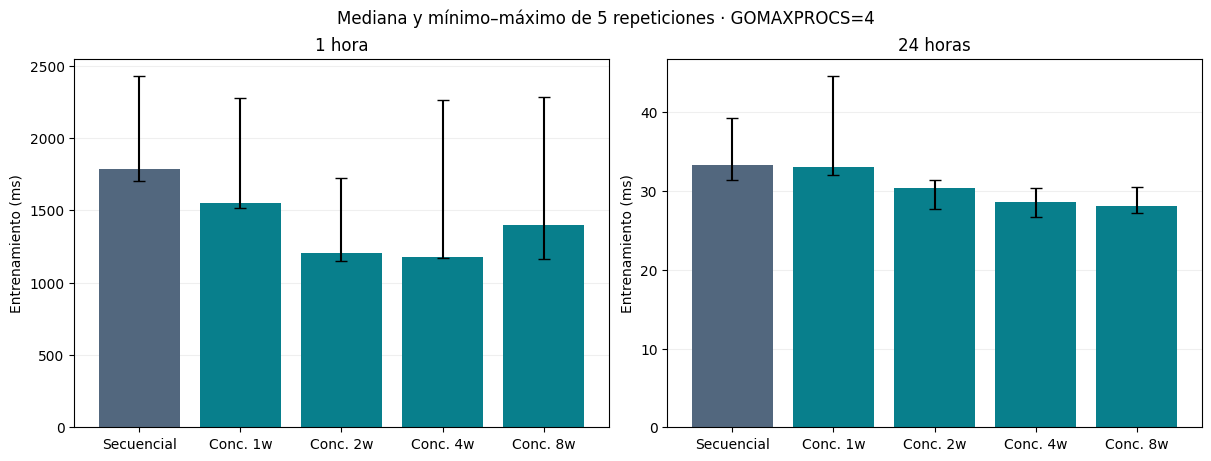

1_hora: menor mediana ML con 4 workers: 1.175477 s; speedup 1.517.
Todas las configuraciones concurrentes medidas tuvieron speedup ML >= 1.
24_horas: menor mediana ML con 8 workers: 0.028048 s; speedup 1.189.
Todas las configuraciones concurrentes medidas tuvieron speedup ML >= 1.


In [31]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
for ax,period in zip(axes,FILES):
    group=summary[summary.Periodo==period]
    labels=['Secuencial' if row.Modo=='sequential' else f'Conc. {row.Workers}w' for row in group.itertuples()]
    values=group['ML (s)'].to_numpy()*1000
    errors=[(group['ML (s)']-group['ML mínimo (s)']).to_numpy()*1000,(group['ML máximo (s)']-group['ML (s)']).to_numpy()*1000]
    ax.bar(labels,values,yerr=errors,capsize=4,color=['#52677e']+['#087f8c']*4)
    ax.set_title(period.replace('_',' '))
    ax.set_ylabel('Entrenamiento (ms)')
    ax.grid(axis='y',alpha=.2)
    ax.set_axisbelow(True)
fig.suptitle('Mediana y mínimo–máximo de 5 repeticiones · GOMAXPROCS=4')
plt.show()

for period in FILES:
    group=summary[(summary.Periodo==period)&(summary.Modo=='concurrent')]
    best=group.loc[group['ML (s)'].idxmin()]
    print(f"{period}: menor mediana ML con {int(best['Workers'])} workers: {best['ML (s)']:.6f} s; speedup {best['Speedup ML']:.3f}.")
    slower=group[group['Speedup ML']<1]
    if len(slower):print('Configuraciones concurrentes más lentas:',list(slower.Workers))
    else:print('Todas las configuraciones concurrentes medidas tuvieron speedup ML >= 1.')
